In [40]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pathlib import Path
import requests

# Download helper_functions.py
helper_file = Path("helper_functions.py")
if not helper_file.is_file():
    print("Download helper_functions.py ...")
    request = requests.get(
        "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py"
    )
    helper_file.write_bytes(request.content)

from helper_functions import plot_predictions, plot_decision_boundary



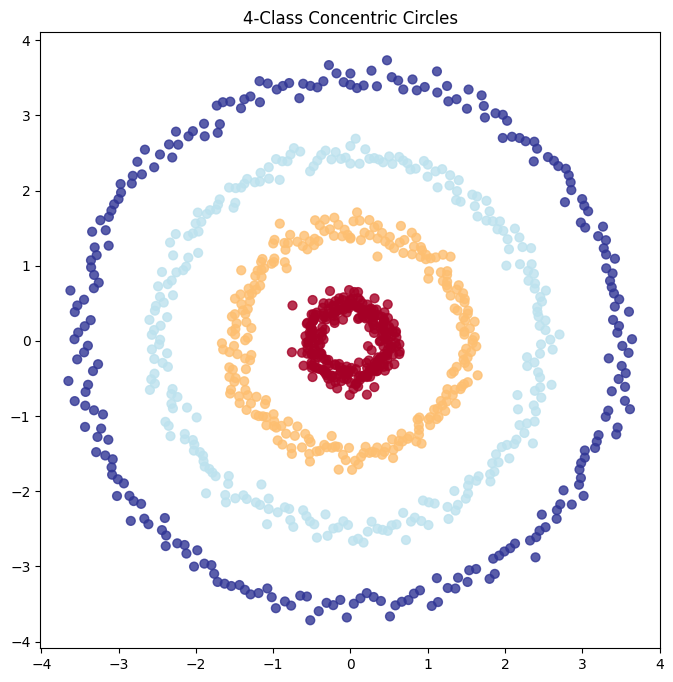

In [41]:
np.random.seed(42)
torch.manual_seed(42)

# generate concentirc rings' data
N = 250 # The number of points of each concentric rings
K = 4   # 4 type
n_samples = N * K
X_circles = np.zeros((n_samples, 2))
y_circles = np.zeros(n_samples, dtype='uint8')

for j in range(K):
    ix = range(N*j, N*(j+1))
    r = j + 0.5 + np.random.randn(N) * 0.1
    t = np.linspace(0, 2*np.pi, N)

    X_circles[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
    y_circles[ix] = j

# Transfer dataset to tensor
X_blob = torch.from_numpy(X_circles).type(torch.float)
y_blob = torch.from_numpy(y_circles).type(torch.long)

# Split into training set and test set

X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(
    X_blob,
    y_blob,
    test_size=0.2,
    random_state=42
)

# Visualization
plt.figure(figsize=(8, 8))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu, s=40, alpha=0.8)
plt.title("4-Class Concentric Circles")
plt.show()

In [42]:
# Calculate accuracy - out of 100 examples, what percentage does our model get right？
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  acc = (correct/len(y_pred)) * 100
  return acc

In [43]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [44]:
# Build a multi-class classification model
class BlobModel(nn.Module):
  def __init__(self, input_features: int, output_features: int, Non_linear: type[nn.Module], hidden_units=8):
    """Initializes multi-class classification model.

    Args:
      input_features (int): Number of input features to the model
      output_features (int): Number of outputs features (number of output classes)
      hidden_units (int): Number of hidden units between layers, default 8
      Non_linear (nn.Module): Type of nonlinear layer (e.g. Non_linear=nn.ReLU)

    Returns:

    Examples:
    """
    super().__init__()
    self.linear_layer_stack = nn.Sequential(
        nn.Linear(in_features=input_features, out_features=hidden_units),
        Non_linear(),
        nn.Linear(in_features=hidden_units, out_features=hidden_units),
        Non_linear(),
        nn.Linear(in_features=hidden_units, out_features=hidden_units),
        Non_linear(),
        nn.Linear(in_features=hidden_units, out_features=output_features)
    )

  def forward(self, x):
    return self.linear_layer_stack(x)

# Create an instance of BlobModel and send it to the target device
model_large = BlobModel(
    input_features=2,
    output_features=4,
    Non_linear=nn.ReLU,
    hidden_units=1024
)

model_small = BlobModel(
    input_features=2,
    output_features=4,
    Non_linear=nn.ReLU,
    hidden_units=8
)

# Create model list
model_lst = [model_large, model_small]

Epoch: 0 | Loss: 1.36900, Train Acc: 26.25% | Test Loss: 54.52483, Test Acc: 24.50%
Epoch: 10 | Loss: 0.92637, Train Acc: 50.38% | Test Loss: 0.83111, Test Acc: 73.50%
Epoch: 20 | Loss: 0.26734, Train Acc: 96.38% | Test Loss: 0.11414, Test Acc: 99.50%
Epoch: 30 | Loss: 0.01439, Train Acc: 100.00% | Test Loss: 0.01937, Test Acc: 99.50%
Epoch: 40 | Loss: 0.00323, Train Acc: 100.00% | Test Loss: 0.00295, Test Acc: 100.00%
Epoch: 50 | Loss: 0.00081, Train Acc: 100.00% | Test Loss: 0.00163, Test Acc: 100.00%
Epoch: 60 | Loss: 0.00048, Train Acc: 100.00% | Test Loss: 0.00098, Test Acc: 100.00%
Epoch: 70 | Loss: 0.00026, Train Acc: 100.00% | Test Loss: 0.00063, Test Acc: 100.00%
Epoch: 80 | Loss: 0.00023, Train Acc: 100.00% | Test Loss: 0.00049, Test Acc: 100.00%
Epoch: 90 | Loss: 0.00019, Train Acc: 100.00% | Test Loss: 0.00042, Test Acc: 100.00%


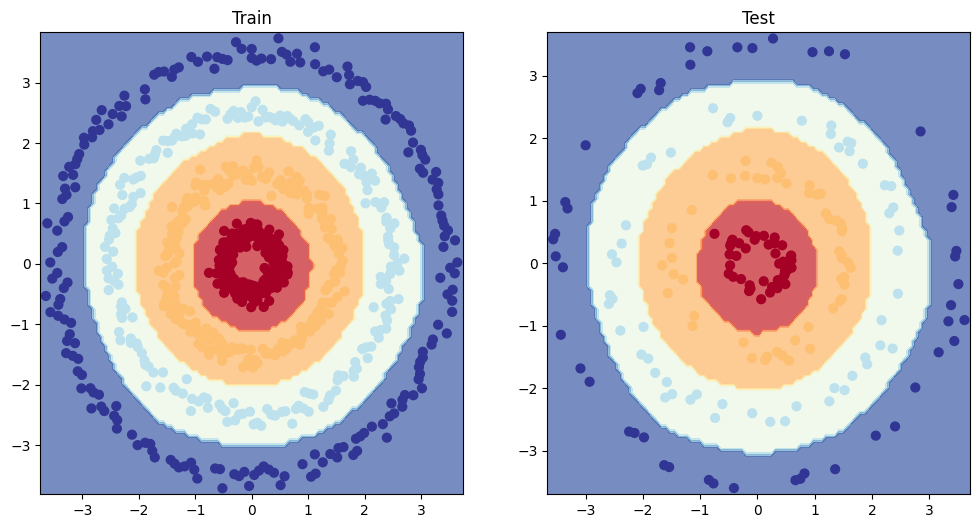

---------------------------------------------------------------------------------------------------------------------------------------------
Epoch: 0 | Loss: 1.39224, Train Acc: 25.75% | Test Loss: 1.38938, Test Acc: 31.50%
Epoch: 10 | Loss: 1.30238, Train Acc: 49.38% | Test Loss: 1.29357, Test Acc: 42.00%
Epoch: 20 | Loss: 1.06680, Train Acc: 53.12% | Test Loss: 1.05957, Test Acc: 46.50%
Epoch: 30 | Loss: 0.77460, Train Acc: 61.75% | Test Loss: 0.77664, Test Acc: 59.00%
Epoch: 40 | Loss: 0.50146, Train Acc: 94.50% | Test Loss: 0.49916, Test Acc: 95.50%
Epoch: 50 | Loss: 0.28016, Train Acc: 98.62% | Test Loss: 0.28227, Test Acc: 98.50%
Epoch: 60 | Loss: 0.14843, Train Acc: 99.38% | Test Loss: 0.15699, Test Acc: 99.50%
Epoch: 70 | Loss: 0.08254, Train Acc: 99.62% | Test Loss: 0.08660, Test Acc: 99.50%
Epoch: 80 | Loss: 0.04490, Train Acc: 99.88% | Test Loss: 0.05006, Test Acc: 100.00%
Epoch: 90 | Loss: 0.02521, Train Acc: 100.00% | Test Loss: 0.03021, Test Acc: 100.00%


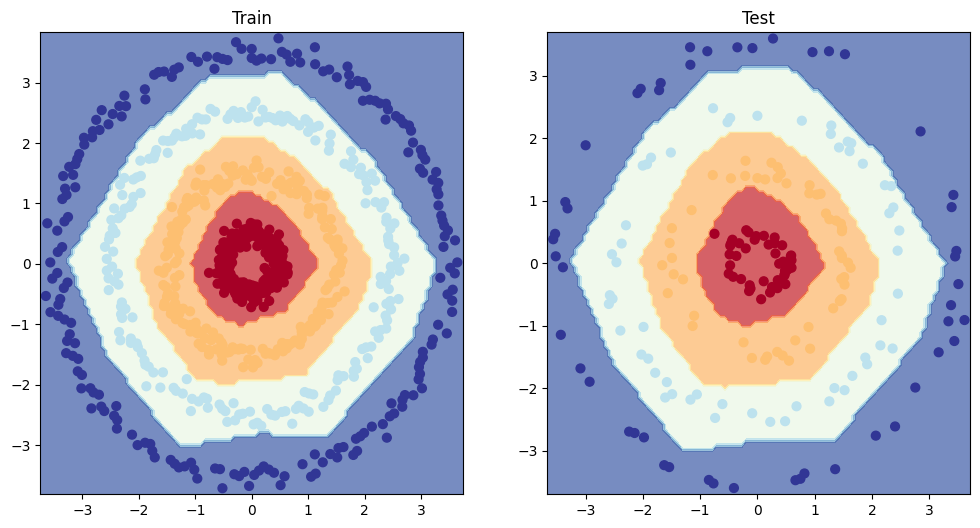

---------------------------------------------------------------------------------------------------------------------------------------------


In [45]:
# Fit the multi-class model to the data
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set number of epochs
epochs = 100

# Put data to the target device
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

# Loop through data

for model in model_lst:

  # Create a loss function for multi-class classification
  loss_fn = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(
    params=model.parameters(),
    lr=0.01
  )

  for epoch in range(epochs):

    model.train()
    y_logits = model(X_blob_train)
    y_prob = torch.softmax(y_logits, dim=1).argmax(dim=1)
    train_loss = loss_fn(y_logits, y_blob_train)
    train_acc = accuracy_fn(
        y_true=y_blob_train,
        y_pred=y_prob
    )
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.inference_mode():
      # 1. forward pass
      test_logits = model(X_blob_test)
      test_prob = torch.softmax(test_logits, dim=1).argmax(dim=1)
      # 2. Calculate test loss and accuracy
      test_loss = loss_fn(test_logits, y_blob_test)
      test_acc = accuracy_fn(
          y_true=y_blob_test,
          y_pred=test_prob
      )

    # Print out what's happening
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {train_loss:.5f}, Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

  # Visualization
  plt.figure(figsize=(12, 6))
  plt.subplot(1, 2, 1)
  plt.title("Train")
  plot_decision_boundary(model, X_blob_train, y_blob_train)
  plt.subplot(1, 2, 2)
  plt.title("Test")
  plot_decision_boundary(model, X_blob_test, y_blob_test)
  plt.show()

  print("---------------------------------------------------------------------------------------------------------------------------------------------")
